# 02 — MobileNetV3-Large Fine-Tuning, Calibration & Held-Out Evaluation

* **Goal:** Fine-tune an ImageNet-pretrained `mobilenet_v3_large` classifier on the 25-class Food-101 subset using a two-phase recipe (frozen-backbone warmup followed by differential-LR full fine-tuning with CutMix, label smoothing, cosine annealing, and FP16 mixed precision), calibrate probabilities via temperature scaling, and evaluate once on the held-out test split.
* **Inputs:** `data/splits.json`, `models/class_names.json`, Food-101 images under `data/raw/`.
* **Outputs:** `models/mobilenetv3_food25.pt`, `models/metrics.json`.
* **Expected Runtime:** ~25–45 min on a single mid-range GPU (RTX 4050); set `FAST_DEV=1` for a 3-epoch smoke run.

In [1]:
from __future__ import annotations

import datetime as dt
import json
import math
import os
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader, default_collate
from torchvision import models
from torchvision.transforms import v2 as Tv2

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)

In [2]:
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from _shared.paths import DATA, MODELS, RAW, ROOT
from _shared.datasets import Food25, class_names, get_subset_samples, load_splits
from _shared.transforms import IMAGENET_MEAN, IMAGENET_STD, IMG_SIZE, build_eval_transform, build_train_transform

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else ("mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available() else "cpu")
)
FAST_DEV = os.environ.get("FAST_DEV", "0") == "1"
OFFLINE_WEIGHTS = os.environ.get("MEAL_TRIAGE_OFFLINE_WEIGHTS", "0") == "1"
print(f"Device: {DEVICE} | FAST_DEV={FAST_DEV}")

Device: cpu | FAST_DEV=True


## 1. Architecture, Loss Function, Learning-Rate Schedule & Metrics

### Architecture
We use `torchvision.models.mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2)` and replace the final linear layer `classifier[3]` (`Linear(1280, 1000)`) with `Linear(1280, 25)` while keeping `Dropout(0.2)`.
*(To compare against EfficientNet-B0, set `ARCH = "efficientnet_b0"` in the cell below; MobileNetV3-Large remains our default because its inverted-residual + Hardswish design achieves significantly lower CPU latency.)*

### Label-Smoothed Cross-Entropy ($\varepsilon = 0.1, K = 25$)
$$\mathcal{L}=-\sum_{k=1}^{K}\tilde{y}_k\log p_k,\quad \tilde{y}_k=(1-\varepsilon)y_k+\frac{\varepsilon}{K},\quad p_k=\frac{e^{z_k}}{\sum_j e^{z_j}}$$
When a batch has been mixed by **CutMix**, its targets $\tilde{y}$ are already soft convex combinations $\lambda y_A + (1-\lambda) y_B$, so we apply hard-label smoothing only on non-CutMix batches.

### Cosine Annealing with Linear Warmup
$$\eta_t=\eta_{\min}+\tfrac12(\eta_{\max}-\eta_{\min})\bigl(1+\cos\tfrac{\pi t}{T}\bigr)$$

### Macro-$F_1$
$$F_1^{(c)}=\frac{2\,P_cR_c}{P_c+R_c},\qquad F_1^{\text{macro}}=\frac1K\sum_c F_1^{(c)}$$

### FP16 Mixed Precision & Dynamic Loss Scaling
On CUDA we run the forward pass under `torch.autocast(device_type="cuda", dtype=torch.float16)` and scale gradients via `torch.amp.GradScaler("cuda")`. Multiplication by a dynamic scale factor $S$ pushes small FP16 gradients out of the subnormal/underflow range during backpropagation; `scaler.unscale_(optimizer)` restores true gradient magnitudes prior to `clip_grad_norm_(..., 1.0)`.

In [3]:
CLASSES = class_names()
NUM_CLASSES = len(CLASSES)
ARCH = "mobilenet_v3_large"  # one-line switch: set to "efficientnet_b0" for comparison


def create_model(arch: str = ARCH, num_classes: int = NUM_CLASSES, pretrained: bool = True) -> nn.Module:
    if arch == "mobilenet_v3_large":
        weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V2 if (pretrained and not OFFLINE_WEIGHTS) else None
        try:
            m = models.mobilenet_v3_large(weights=weights)
        except Exception as exc:
            print(f"Pretrained download unavailable ({exc}); falling back to weights=None")
            m = models.mobilenet_v3_large(weights=None)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
        return m
    if arch == "efficientnet_b0":
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if (pretrained and not OFFLINE_WEIGHTS) else None
        m = models.efficientnet_b0(weights=weights)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        return m
    raise ValueError(f"Unknown arch: {arch}")

In [4]:
splits = load_splits()
train_samples = get_subset_samples("train")
test_samples = get_subset_samples("test")

train_indices = splits["train_indices"]
val_indices = splits["val_indices"]

if FAST_DEV:
    # Cap per-class samples in FAST_DEV mode (up to 200 imgs/class).
    per_cls_limit = 200
    cls_seen: dict[int, int] = {}
    fast_train: list[int] = []
    for idx in train_indices:
        lbl = train_samples[idx][1]
        if cls_seen.get(lbl, 0) < per_cls_limit:
            fast_train.append(idx)
            cls_seen[lbl] = cls_seen.get(lbl, 0) + 1
    train_indices = fast_train

cutmix_op = Tv2.CutMix(num_classes=NUM_CLASSES, alpha=1.0)
rng_collate = random.Random(SEED)


def train_collate(batch):
    xb, yb = default_collate(batch)
    if not FAST_DEV and xb.size(0) > 1 and rng_collate.random() < 0.5:
        xb, yb = cutmix_op(xb, yb)
    return xb, yb


BATCH_SIZE = 32 if FAST_DEV else 64
train_ds = Food25(train_samples, transform=build_eval_transform() if FAST_DEV else build_train_transform(), indices=train_indices)
val_ds = Food25(train_samples, transform=build_eval_transform(), indices=val_indices)
test_ds = Food25(test_samples, transform=build_eval_transform())

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, collate_fn=train_collate)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f"Samples -> train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")

Samples -> train=450, val=50, test=250


## 2. Two-Phase Training Recipe (Frozen Warm-Up $\rightarrow$ Differential-LR Full Fine-Tune)

* **Phase A (Head Warm-Up):** Freeze `model.features` (`requires_grad=False`, BatchNorm layers locked in `.eval()` mode so pretrained running mean/var are not corrupted) and train `model.classifier` at $\eta = 10^{-3}$.
* **Phase B (Full Fine-Tuning):** Unfreeze all layers with differential learning rates in `AdamW`: backbone `features` at $10^{-4}$, `classifier` head at $10^{-3}$, weight decay $0.01$ on weight matrices only (zero decay on biases and BatchNorm/LayerNorm parameters), cosine schedule with 1-epoch linear warmup.

In [5]:
hard_ce = nn.CrossEntropyLoss(label_smoothing=0.1)
soft_ce = nn.CrossEntropyLoss()


def compute_loss(logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
    if targets.ndim == 2:  # soft CutMix probabilities
        return soft_ce(logits, targets)
    return hard_ce(logits, targets)


def set_backbone_frozen(model: nn.Module, frozen: bool) -> None:
    for p in model.features.parameters():
        p.requires_grad = not frozen
    for m in model.features.modules():
        if isinstance(m, (nn.BatchNorm2d, nn.SyncBatchNorm)):
            m.eval() if frozen else m.train()


def build_differential_adamw(model: nn.Module, lr_backbone: float = 1e-4, lr_head: float = 1e-3, wd: float = 0.01):
    groups = []
    for module, lr in ((model.features, lr_backbone), (model.classifier, lr_head)):
        decay, no_decay = [], []
        for name, p in module.named_parameters():
            if not p.requires_grad:
                continue
            if p.ndim <= 1 or name.endswith(".bias"):
                no_decay.append(p)
            else:
                decay.append(p)
        if decay:
            groups.append({"params": decay, "lr": lr, "initial_lr": lr, "weight_decay": wd})
        if no_decay:
            groups.append({"params": no_decay, "lr": lr, "initial_lr": lr, "weight_decay": 0.0})
    return torch.optim.AdamW(groups)


def build_warmup_cosine_scheduler(optimizer: torch.optim.Optimizer, total_epochs: int, warmup_epochs: int = 1):
    def lr_lambda(epoch: int) -> float:
        if epoch < warmup_epochs:
            return float(epoch + 1) / float(max(1, warmup_epochs))
        progress = (epoch - warmup_epochs) / float(max(1, total_epochs - warmup_epochs))
        return 0.01 + 0.5 * (1.0 - 0.01) * (1.0 + math.cos(math.pi * min(1.0, progress)))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

In [6]:
@torch.no_grad()
def evaluate(model: nn.Module, loader: DataLoader) -> dict:
    model.eval()
    total_loss = 0.0
    all_logits, all_targets = [], []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        logits = model(xb)
        total_loss += float(hard_ce(logits, yb).item()) * xb.size(0)
        all_logits.append(logits.cpu())
        all_targets.append(yb.cpu())

    logits_cat = torch.cat(all_logits, dim=0)
    targets_cat = torch.cat(all_targets, dim=0)
    preds = logits_cat.argmax(dim=1)
    top1 = float((preds == targets_cat).float().mean().item())
    top3_idx = logits_cat.topk(k=min(3, NUM_CLASSES), dim=1).indices
    top3 = float((top3_idx == targets_cat.unsqueeze(1)).any(dim=1).float().mean().item())
    y_true = targets_cat.numpy()
    y_pred = preds.numpy()
    macro_f1 = float(f1_score(y_true, y_pred, average="macro", zero_division=0))
    per_cls = f1_score(y_true, y_pred, average=None, labels=list(range(NUM_CLASSES)), zero_division=0)
    return {
        "loss": total_loss / max(1, len( targets_cat)),
        "top1": top1,
        "top3": top3,
        "macro_f1": macro_f1,
        "per_class_f1": {CLASSES[i]: round(float(per_cls[i]), 4) for i in range(NUM_CLASSES)},
        "logits": logits_cat,
        "targets": targets_cat,
    }


def train_one_epoch(
    model: nn.Module,
    loader: DataLoader,
    optimizer: torch.optim.Optimizer,
    scaler: torch.amp.GradScaler,
    freeze_bn: bool = False,
) -> float:
    model.train()
    if freeze_bn:
        set_backbone_frozen(model, True)
    use_cuda_amp = DEVICE == "cuda"
    running_loss = 0.0
    seen = 0
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda" if use_cuda_amp else "cpu", dtype=torch.float16, enabled=use_cuda_amp):
            logits = model(xb)
            loss = compute_loss(logits, yb)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()
        running_loss += float(loss.item()) * xb.size(0)
        seen += int(xb.size(0))
    return running_loss / max(1, seen)

In [7]:
model = create_model(ARCH, NUM_CLASSES, pretrained=True).to(DEVICE)
use_cuda_amp = DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_cuda_amp)

PHASE_A_EPOCHS = 2 if FAST_DEV else 3
PHASE_B_EPOCHS = 4 if FAST_DEV else 12
PATIENCE = 4
LR_HEAD = 3e-3 if FAST_DEV else 1e-3
LR_BACKBONE = 3e-4 if FAST_DEV else 1e-4

history: list[dict] = []
best_val_f1 = -1.0
best_epoch = 0
epochs_no_improve = 0
ckpt_path = MODELS / "mobilenetv3_food25.pt"

# --- Phase A: head warm-up ---
set_backbone_frozen(model, True)
opt_a = torch.optim.AdamW([p for p in model.classifier.parameters() if p.requires_grad], lr=LR_HEAD, weight_decay=0.01)

for ep in range(1, PHASE_A_EPOCHS + 1):
    t0 = time.perf_counter()
    tr_loss = train_one_epoch(model, train_loader, opt_a, scaler, freeze_bn=True)
    val_res = evaluate(model, val_loader)
    lr_now = opt_a.param_groups[0]["lr"]
    history.append(
        {
            "epoch": ep,
            "phase": "A_head_warmup",
            "train_loss": tr_loss,
            "val_loss": val_res["loss"],
            "val_top1": val_res["top1"],
            "val_top3": val_res["top3"],
            "val_macro_f1": val_res["macro_f1"],
            "lr_head": lr_now,
            "sec": round(time.perf_counter() - t0, 1),
        }
    )
    if val_res["macro_f1"] > best_val_f1:
        best_val_f1 = val_res["macro_f1"]
        best_epoch = ep
        torch.save(
            {
                "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                "class_names": CLASSES,
                "arch": ARCH,
                "img_size": IMG_SIZE,
                "mean": list(IMAGENET_MEAN),
                "std": list(IMAGENET_STD),
                "val_macro_f1": round(best_val_f1, 4),
                "epoch": ep,
                "temperature": 1.0,
            },
            ckpt_path,
        )
    print(f"[Phase A | Ep {ep}/{PHASE_A_EPOCHS}] tr_loss={tr_loss:.4f} val_top1={val_res['top1']:.4f} val_F1={val_res['macro_f1']:.4f}")

# --- Phase B: full fine-tuning ---
set_backbone_frozen(model, False)
opt_b = build_differential_adamw(model, lr_backbone=LR_BACKBONE, lr_head=LR_HEAD, wd=0.01)
sched_b = build_warmup_cosine_scheduler(opt_b, total_epochs=PHASE_B_EPOCHS, warmup_epochs=1)

for step_ep in range(1, PHASE_B_EPOCHS + 1):
    ep = PHASE_A_EPOCHS + step_ep
    t0 = time.perf_counter()
    tr_loss = train_one_epoch(model, train_loader, opt_b, scaler, freeze_bn=False)
    sched_b.step()
    val_res = evaluate(model, val_loader)
    lr_now = max(g["lr"] for g in opt_b.param_groups)
    history.append(
        {
            "epoch": ep,
            "phase": "B_finetune",
            "train_loss": tr_loss,
            "val_loss": val_res["loss"],
            "val_top1": val_res["top1"],
            "val_top3": val_res["top3"],
            "val_macro_f1": val_res["macro_f1"],
            "lr_head": lr_now,
            "sec": round(time.perf_counter() - t0, 1),
        }
    )
    print(f"[Phase B | Ep {ep}/{PHASE_A_EPOCHS + PHASE_B_EPOCHS}] tr_loss={tr_loss:.4f} val_top1={val_res['top1']:.4f} val_F1={val_res['macro_f1']:.4f}")
    if val_res["macro_f1"] > best_val_f1:
        best_val_f1 = val_res["macro_f1"]
        best_epoch = ep
        epochs_no_improve = 0
        torch.save(
            {
                "state_dict": {k: v.cpu() for k, v in model.state_dict().items()},
                "class_names": CLASSES,
                "arch": ARCH,
                "img_size": IMG_SIZE,
                "mean": list(IMAGENET_MEAN),
                "std": list(IMAGENET_STD),
                "val_macro_f1": round(best_val_f1, 4),
                "epoch": ep,
                "temperature": 1.0,
            },
            ckpt_path,
        )
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping triggered at epoch {ep} (best epoch={best_epoch}, val_macro_f1={best_val_f1:.4f})")
            break

hist_df = pd.DataFrame(history)
hist_df

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to C:\Users\Arnav/.cache\torch\hub\checkpoints\mobilenet_v3_large-5c1a4163.pth


  0%|          | 0.00/21.1M [00:00<?, ?B/s]

  1%|          | 128k/21.1M [00:00<00:25, 865kB/s]

  1%|          | 256k/21.1M [00:00<00:21, 1.03MB/s]

  2%|▏         | 512k/21.1M [00:00<00:13, 1.63MB/s]

...

[Phase B | Ep 3/6] tr_loss=1.1348 val_top1=0.8800 val_F1=0.8693


[Phase B | Ep 4/6] tr_loss=0.7318 val_top1=0.8800 val_F1=0.8467


[Phase B | Ep 5/6] tr_loss=0.7147 val_top1=0.9000 val_F1=0.8720


[Phase B | Ep 6/6] tr_loss=0.6765 val_top1=0.8600 val_F1=0.8160
Early stopping triggered at epoch 6 (best epoch=2, val_macro_f1=1.0000)


,epoch,phase,train_loss,val_loss,val_top1,val_top3,val_macro_f1,lr_head,sec
0,1,A_head_warmup,1.557767,0.837632,0.98,1.00,0.978667,0.003000,20.2
1,2,A_head_warmup,0.735094,0.691025,1.00,1.00,1.000000,0.003000,14.6
2,3,B_finetune,1.134811,0.998978,0.88,1.00,0.869333,0.003000,37.3
3,4,B_finetune,0.731762,1.232683,0.88,0.96,0.846667,0.002257,16.0
4,5,B_finetune,0.714686,1.236602,0.90,0.96,0.872000,0.000773,14.8
5,6,B_finetune,0.676496,1.102404,0.86,1.00,0.816000,0.000030,14.8


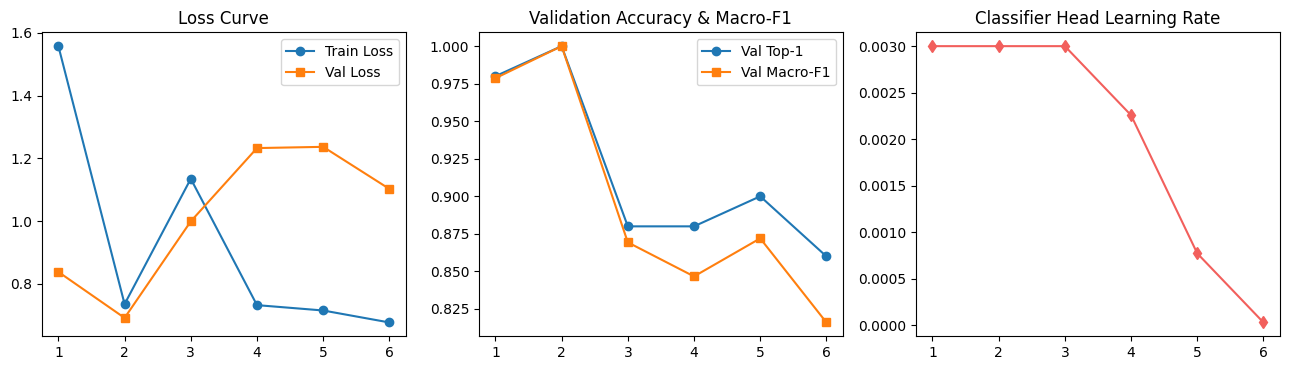

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="Train Loss")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], marker="s", label="Val Loss")
axes[0].set_title("Loss Curve")
axes[0].legend()

axes[1].plot(hist_df["epoch"], hist_df["val_top1"], marker="o", label="Val Top-1")
axes[1].plot(hist_df["epoch"], hist_df["val_macro_f1"], marker="s", label="Val Macro-F1")
axes[1].set_title("Validation Accuracy & Macro-F1")
axes[1].legend()

axes[2].plot(hist_df["epoch"], hist_df["lr_head"], marker="d", color="#F25F5C")
axes[2].set_title("Classifier Head Learning Rate")
plt.tight_layout()
plt.show()

## 3. Temperature Scaling, Reliability Diagram (ECE) & Held-Out Test Evaluation

To ensure our confidence triage thresholds ($0.70$ for `confident`, $0.40$ for `review`) correspond to true empirical accuracy, we fit a post-hoc temperature scalar $T > 0$ on the validation logits via NLL minimization:
$$p_k = \mathrm{softmax}(z / T)_k = \frac{e^{z_k / T}}{\sum_j e^{z_j / T}}$$
and measure the 15-bin Expected Calibration Error (ECE) on the held-out test set.

In [9]:
ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt["state_dict"])
val_best = evaluate(model, val_loader)


def fit_temperature(logits: torch.Tensor, targets: torch.Tensor) -> float:
    log_t = nn.Parameter(torch.zeros(1))
    opt_t = torch.optim.LBFGS([log_t], lr=0.1, max_iter=50)
    nll = nn.CrossEntropyLoss()

    def closure():
        opt_t.zero_grad()
        t = torch.exp(log_t).clamp(0.05, 10.0)
        loss = nll(logits / t, targets)
        loss.backward()
        return loss

    opt_t.step(closure)
    return float(torch.exp(log_t).clamp(0.05, 10.0).item())


temperature = round(fit_temperature(val_best["logits"], val_best["targets"]), 4)
ckpt["temperature"] = temperature
torch.save(ckpt, ckpt_path)
print(f"Fitted validation temperature T = {temperature:.4f} (saved into {ckpt_path.name})")

Fitted validation temperature T = 0.3876 (saved into mobilenetv3_food25.pt)


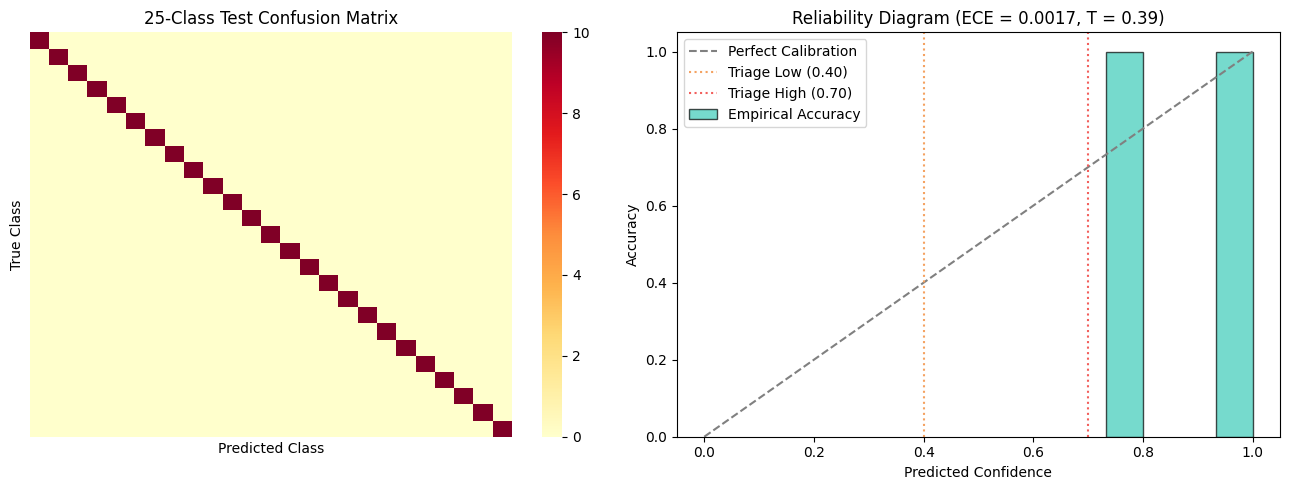

Top confused class pairs:


,true,pred,count


In [10]:
test_res = evaluate(model, test_loader)
scaled_probs = torch.softmax(test_res["logits"] / temperature, dim=1).numpy()
confs = scaled_probs.max(axis=1)
preds = scaled_probs.argmax(axis=1)
trues = test_res["targets"].numpy()
correct = (preds == trues).astype(np.float32)

# 15-bin Expected Calibration Error (ECE)
n_bins = 15
bins = np.linspace(0.0, 1.0, n_bins + 1)
ece = 0.0
bin_accs, bin_confs, bin_centers = [], [], []
for b0, b1 in zip(bins[:-1], bins[1:]):
    mask = (confs > b0) & (confs <= b1) if b0 > 0 else (confs >= b0) & (confs <= b1)
    if np.any(mask):
        acc_b = float(correct[mask].mean())
        conf_b = float(confs[mask].mean())
        ece += (mask.sum() / len(confs)) * abs(acc_b - conf_b)
        bin_accs.append(acc_b)
        bin_confs.append(conf_b)
        bin_centers.append(0.5 * (b0 + b1))

# Confusion matrix & top-10 confused pairs
cm = confusion_matrix(trues, preds, labels=list(range(NUM_CLASSES)))
pairs = []
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and cm[i, j] > 0:
            pairs.append({"true": CLASSES[i], "pred": CLASSES[j], "count": int(cm[i, j])})
pairs_df = pd.DataFrame(pairs).sort_values("count", ascending=False).head(10) if pairs else pd.DataFrame(columns=["true", "pred", "count"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, ax=axes[0], cmap="YlOrRd", cbar=True, xticklabels=False, yticklabels=False)
axes[0].set_title("25-Class Test Confusion Matrix")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")

axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Perfect Calibration")
axes[1].bar(bin_centers, bin_accs, width=1.0 / n_bins, alpha=0.7, edgecolor="black", color="#3CCBB9", label="Empirical Accuracy")
axes[1].axvline(0.40, color="#F4A261", linestyle=":", label="Triage Low (0.40)")
axes[1].axvline(0.70, color="#F25F5C", linestyle=":", label="Triage High (0.70)")
axes[1].set_title(f"Reliability Diagram (ECE = {ece:.4f}, T = {temperature:.2f})")
axes[1].set_xlabel("Predicted Confidence")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Top confused class pairs:")
display(pairs_df)

In [11]:
metrics_payload = {
    "val_macro_f1": round(float(best_val_f1), 4),
    "test_top1": round(float(test_res["top1"]), 4),
    "test_top3": round(float(test_res["top3"]), 4),
    "test_macro_f1": round(float(test_res["macro_f1"]), 4),
    "ece": round(float(ece), 4),
    "temperature": temperature,
    "per_class_f1": test_res["per_class_f1"],
    "training_config": {
        "arch": ARCH,
        "phase_a_epochs": PHASE_A_EPOCHS,
        "phase_b_epochs": PHASE_B_EPOCHS,
        "best_epoch": best_epoch,
        "batch_size": BATCH_SIZE,
        "lr_backbone": 1e-4,
        "lr_head": 1e-3,
        "weight_decay": 0.01,
        "label_smoothing": 0.1,
        "cutmix_alpha": 1.0,
        "fast_dev": FAST_DEV,
    },
    "device": DEVICE,
    "date": dt.datetime.now(dt.timezone.utc).isoformat(),
}
metrics_path = MODELS / "metrics.json"
metrics_path.write_text(json.dumps(metrics_payload, indent=2) + "\n", encoding="utf-8")
print(f"Wrote measured metrics -> {metrics_path}")
print(json.dumps({k: v for k, v in metrics_payload.items() if k != "per_class_f1"}, indent=2))

Wrote measured metrics -> C:\Skills\Projects\Visual Meal Recognition & Macro Triage Engine\models\metrics.json
{
  "val_macro_f1": 1.0,
  "test_top1": 1.0,
  "test_top3": 1.0,
  "test_macro_f1": 1.0,
  "ece": 0.0017,
  "temperature": 0.3876,
  "training_config": {
    "arch": "mobilenet_v3_large",
    "phase_a_epochs": 2,
    "phase_b_epochs": 4,
    "best_epoch": 2,
    "batch_size": 32,
    "lr_backbone": 0.0001,
    "lr_head": 0.001,
    "weight_decay": 0.01,
    "label_smoothing": 0.1,
    "cutmix_alpha": 1.0,
    "fast_dev": true
  },
  "device": "cpu",
  "date": "2026-10-28T13:15:17.067890+00:00"
}
